# 14. Falki na grafach, na sferze i w dowolnym kierunku

**Arkadiusz Liber** · *Falki w praktyce. Od wzoru do kodu*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/blob/main/rozdzial-14.ipynb)

Notatnik do książki. Zawiera wszystkie programy z tekstu rozdziału oraz ćwiczenia z rozwiązaniami.

Notatnik działa lokalnie (Jupyter) i w Google Colab. Komórki można uruchamiać po kolei poleceniem *Uruchom wszystko*.

In [1]:
# Uruchom tę komórkę jako pierwszą (lokalnie albo w Google Colab).
import sys, subprocess, importlib.util, os
if importlib.util.find_spec("pywt") is None:      # PyWavelets
    subprocess.check_call([sys.executable, "-m", "pip",
                           "install", "-q", "PyWavelets"])
import numpy as np
import matplotlib.pyplot as plt
import pywt

SZARY, NIEBIESKI, RDZAWY, ZIELONY = "#757575", "#1273E2", "#D93B0B", "#078832"
FIOLET, BURSZTYN = "#9258D5", "#B36000"
plt.rcParams.update({
    "text.color": SZARY, "axes.labelcolor": SZARY, "axes.edgecolor": SZARY,
    "xtick.color": SZARY, "ytick.color": SZARY, "axes.titlecolor": SZARY,
    "font.size": 10, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False})

# Dane z obserwatorium SDO używane w tym rozdziale.
# Courtesy of NASA/SDO and the AIA, EVE, and HMI science teams
DANE = "dane/sdo-20240115.npz"
if not os.path.exists(DANE):                 # np. Google Colab: pobranie z repozytorium
    import urllib.request
    os.makedirs("dane", exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/main/dane/sdo-20240115.npz", DANE)


## Programy z tekstu rozdziału

### Kod 14.1. Graf-ścieżka: wektory własne laplasjanu są kosinusami

In [2]:
import numpy as np
from scipy.fft import idct

n = 64
W = np.zeros((n, n))
i = np.arange(n - 1)
W[i, i + 1] = W[i + 1, i] = 1                  # sąsiednie próbki
L = np.diag(W.sum(axis=1)) - W                 # laplasjan (14.1)
lam, U = np.linalg.eigh(L)

k = np.arange(n)
print(np.allclose(lam, 2 - 2*np.cos(np.pi*k/n)))
C = idct(np.eye(n), norm="ortho", axis=0)      # kolumny: baza kosinusowa
print(np.allclose(np.abs(np.sum(U*C, axis=0)), 1))

s = np.exp(-((k - 20)/6.0)**2)
print("gładkość s^T L s:", round(float(s @ L @ s), 4), " suma kwadratów "
      "różnic:", round(float(np.sum(np.diff(s)**2)), 4))

True
True
gładkość s^T L s: 0.2074  suma kwadratów różnic: 0.2074


### Kod 14.2. Falki na grafie sieci czujników: rama ciasna i lokalizacja

In [3]:
import numpy as np
from scipy.sparse.csgraph import shortest_path
from scipy.spatial import cKDTree
from scipy.special import betainc

def siec(n=400, k=6, ziarno=0):
    """Losowa sieć czujników: każdy połączony z k najbliższymi."""
    P = np.random.default_rng(ziarno).uniform(size=(n, 2))
    odl, sasiad = cKDTree(P).query(P, k + 1)
    W = np.zeros((n, n))
    wiersz = np.repeat(np.arange(n), k)
    W[wiersz, sasiad[:, 1:].ravel()] = np.exp(
        -odl[:, 1:].ravel()**2/(2*np.median(odl[:, 1:])**2))
    return P, np.maximum(W, W.T)               # macierz wag, symetryczna

def jadra(lam, lmax, J):
    """Jądra ramy ciasnej: J pasm falkowych i pasmo dolne."""
    nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))
    u = np.log2(np.maximum(lam, 1e-12)/lmax)   # 0 dla największej
    G = [np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                  np.sin(np.pi/2*nu(u + j + 1))) for j in range(J)]
    G[0] = np.sin(np.pi/2*nu(u + 1))
    return np.array(G), np.cos(np.pi/2*nu(u + J))

P, W = siec()
L = np.diag(W.sum(axis=1)) - W
lam, U = np.linalg.eigh(L)
J = 5
G, h = jadra(lam, lam[-1], J)
print("węzłów:", len(P), " średnia liczba sąsiadów:",
      round(float((W > 0).sum(axis=1).mean()), 1),
      " największa wartość własna:", round(float(lam[-1]), 2))
print("suma kwadratów jąder:", np.allclose(np.sum(G**2, axis=0) + h**2, 1))

rng = np.random.default_rng(1)
f = rng.normal(size=len(P))
widmo = U.T @ f                                # grafowa transformata Fouriera
wsp = np.array([U @ (g*widmo) for g in G])     # współczynniki falkowe (14.4)
dolne = U @ (h*widmo)
print("energia:", np.isclose(np.sum(wsp**2) + np.sum(dolne**2), np.sum(f**2)))
odtw = sum(U @ (g*(U.T @ w)) for g, w in zip(G, wsp)) + U @ (h*(U.T @ dolne))
print("odtworzenie:", np.allclose(odtw, f))

skoki = shortest_path(W > 0, unweighted=True)  # odległość w krawędziach
srodek = np.argmin(np.linalg.norm(P - 0.5, axis=1))
for j in range(J):
    psi = U @ (G[j]*U[srodek])                 # falka w węźle środkowym
    e = psi**2/np.sum(psi**2)
    print(f"pasmo {j}: wartości własnych {int(np.sum(G[j] > 0.5)):3d}, "
          f"energia falki do 2 skoków {100*e[skoki[srodek] <= 2].sum():5.1f}%"
          f", średni zasięg {np.sum(e*skoki[srodek]):.2f} skoku")

węzłów: 400  średnia liczba sąsiadów: 7.2  największa wartość własna: 8.99
suma kwadratów jąder: True
energia: True
odtworzenie: True
pasmo 0: wartości własnych  65, energia falki do 2 skoków  97.2%, średni zasięg 0.98 skoku
pasmo 1: wartości własnych 251, energia falki do 2 skoków  98.2%, średni zasięg 0.24 skoku
pasmo 2: wartości własnych  74, energia falki do 2 skoków  66.5%, średni zasięg 2.00 skoku
pasmo 3: wartości własnych  31, energia falki do 2 skoków  48.7%, średni zasięg 2.72 skoku
pasmo 4: wartości własnych  15, energia falki do 2 skoków  40.7%, średni zasięg 3.37 skoku


### Kod 14.3. Falki grafowe bez rozkładu własnego: przybliżenie wielomianami Czebyszewa

In [4]:
import numpy as np
from scipy import sparse
from scipy.spatial import cKDTree
from scipy.special import betainc

def siec(n=400, k=6, ziarno=0):
    """Losowa sieć czujników: każdy połączony z k najbliższymi."""
    P = np.random.default_rng(ziarno).uniform(size=(n, 2))
    odl, sasiad = cKDTree(P).query(P, k + 1)
    W = np.zeros((n, n))
    wiersz = np.repeat(np.arange(n), k)
    W[wiersz, sasiad[:, 1:].ravel()] = np.exp(
        -odl[:, 1:].ravel()**2/(2*np.median(odl[:, 1:])**2))
    return P, np.maximum(W, W.T)               # macierz wag, symetryczna

def jadra(lam, lmax, J):
    """Jądra ramy ciasnej: J pasm falkowych i pasmo dolne."""
    nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))
    u = np.log2(np.maximum(lam, 1e-12)/lmax)   # 0 dla największej
    G = [np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                  np.sin(np.pi/2*nu(u + j + 1))) for j in range(J)]
    G[0] = np.sin(np.pi/2*nu(u + 1))
    return np.array(G), np.cos(np.pi/2*nu(u + J))

def czebyszew(L, f, jadro, lmax, M):
    """Przybliża jadro(L) f wielomianem stopnia M macierzy L."""
    kat = np.pi*(np.arange(200) + 0.5)/200
    c = 2/200*np.cos(np.outer(np.arange(M + 1), kat)) @ jadro(
        lmax/2*(np.cos(kat) + 1))              # współczynniki rozwinięcia
    T0, T1 = f, (2/lmax)*(L @ f) - f
    wynik = c[0]/2*T0 + c[1]*T1
    for m in range(2, M + 1):                  # rekurencja (14.6)
        T0, T1 = T1, (4/lmax)*(L @ T1) - 2*T1 - T0
        wynik = wynik + c[m]*T1
    return wynik

P, W = siec()
Lg = np.diag(W.sum(axis=1)) - W
L = sparse.csr_matrix(Lg)                      # macierz rzadka
lam, U = np.linalg.eigh(Lg)                    # tylko do porównania
lmax, J = lam[-1], 5
f = np.random.default_rng(1).normal(size=len(P))
print("niezerowych elementów laplasjanu:", L.nnz, "z", len(P)**2)
for j in (0, 2, 4):
    dokladnie = U @ (jadra(lam, lmax, J)[0][j]*(U.T @ f))
    opis = f"pasmo {j}: błąd"
    for M in (10, 20, 40, 80):
        y = czebyszew(L, f, lambda x: jadra(x, lmax, J)[0][j], lmax, M)
        blad = np.linalg.norm(y - dokladnie)/np.linalg.norm(dokladnie)
        opis += f"  M = {M}: {100*blad:6.2f}%"
    print(opis)

niezerowych elementów laplasjanu: 3272 z 160000
pasmo 0: błąd  M = 10:   6.08%  M = 20:   0.25%  M = 40:   0.02%  M = 80:   0.00%
pasmo 2: błąd  M = 10:  13.50%  M = 20:   6.95%  M = 40:   0.60%  M = 80:   0.02%
pasmo 4: błąd  M = 10:  61.18%  M = 20:  21.69%  M = 40:  13.45%  M = 80:   1.41%


### Kod 14.4. Wykrywanie uszkodzonego czujnika: falki grafowe i dwie metody prostsze

In [5]:
import numpy as np
from scipy.spatial import cKDTree
from scipy.special import betainc

def siec(n=400, k=6, ziarno=0):
    """Losowa sieć czujników: każdy połączony z k najbliższymi."""
    P = np.random.default_rng(ziarno).uniform(size=(n, 2))
    odl, sasiad = cKDTree(P).query(P, k + 1)
    W = np.zeros((n, n))
    wiersz = np.repeat(np.arange(n), k)
    W[wiersz, sasiad[:, 1:].ravel()] = np.exp(
        -odl[:, 1:].ravel()**2/(2*np.median(odl[:, 1:])**2))
    return P, np.maximum(W, W.T)               # macierz wag, symetryczna

def jadra(lam, lmax, J):
    """Jądra ramy ciasnej: J pasm falkowych i pasmo dolne."""
    nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))
    u = np.log2(np.maximum(lam, 1e-12)/lmax)   # 0 dla największej
    G = [np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                  np.sin(np.pi/2*nu(u + j + 1))) for j in range(J)]
    G[0] = np.sin(np.pi/2*nu(u + 1))
    return np.array(G), np.cos(np.pi/2*nu(u + J))

P, W = siec()
x, y = P.T
lam, U = np.linalg.eigh(np.diag(W.sum(axis=1)) - W)
G, h = jadra(lam, lam[-1], 5)
gorne = np.sqrt(G[0]**2 + G[1]**2)             # dwa najwyższe pasma
norma = np.sqrt(np.sum((U*gorne)**2, axis=1))  # norma falki w każdym węźle
sasiedzi = W > 0

rng = np.random.default_rng(2)
print("błąd   falki  sąsiedzi  cała sieć   (trafne wskazania na 100)")
for blad in (1.5, 2.0, 3.0):
    trafienia = np.zeros(3)
    for proba in range(300):
        f = (20 + 8*np.sin(2*np.pi*x)*np.cos(np.pi*y) + 5*x
             + 0.3*rng.normal(size=len(P)))    # pole temperatury i szum
        zly = rng.integers(len(P))
        f[zly] += blad*rng.choice([-1, 1])     # uszkodzony czujnik
        miary = (np.abs(U @ (gorne*(U.T @ f)))/norma,
                 np.abs(f - (sasiedzi @ f)/sasiedzi.sum(axis=1)),
                 np.abs(f - np.median(f)))
        trafienia += [np.argmax(m) == zly for m in miary]
    print(f"{blad:4.1f} {trafienia[0]/3:7.0f} {trafienia[1]/3:8.0f} "
          f"{trafienia[2]/3:10.0f}")

błąd   falki  sąsiedzi  cała sieć   (trafne wskazania na 100)
 1.5      26        5          2
 2.0      63        9          3
 3.0      93       66          7


### Kod 14.5. Odszumianie sygnału na grafie: progowanie w ramie falkowej i filtry gładzące

In [6]:
import numpy as np
from scipy.spatial import cKDTree
from scipy.special import betainc

def siec(n=400, k=6, ziarno=0):
    """Losowa sieć czujników: każdy połączony z k najbliższymi."""
    P = np.random.default_rng(ziarno).uniform(size=(n, 2))
    odl, sasiad = cKDTree(P).query(P, k + 1)
    W = np.zeros((n, n))
    wiersz = np.repeat(np.arange(n), k)
    W[wiersz, sasiad[:, 1:].ravel()] = np.exp(
        -odl[:, 1:].ravel()**2/(2*np.median(odl[:, 1:])**2))
    return P, np.maximum(W, W.T)               # macierz wag, symetryczna

def jadra(lam, lmax, J):
    """Jądra ramy ciasnej: J pasm falkowych i pasmo dolne."""
    nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))
    u = np.log2(np.maximum(lam, 1e-12)/lmax)   # 0 dla największej
    G = [np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                  np.sin(np.pi/2*nu(u + j + 1))) for j in range(J)]
    G[0] = np.sin(np.pi/2*nu(u + 1))
    return np.array(G), np.cos(np.pi/2*nu(u + J))

P, W = siec()
x, y = P.T
lam, U = np.linalg.eigh(np.diag(W.sum(axis=1)) - W)
G, h = jadra(lam, lam[-1], 5)
normy = [np.sqrt(np.sum((U*g)**2, axis=1)) for g in G]
sasiedzi = W > 0

# sygnał gładki po obu stronach krzywej, ze skokiem na krzywej
s = np.where(x + 0.3*np.sin(3*y) < 0.5, 10 + 3*y, 18 - 2*x)
sigma = 0.5
snr = lambda e: 10*np.log10(np.sum((s - s.mean())**2)/np.sum((s - e)**2))
rng = np.random.default_rng(3)
wyniki = {}
for proba in range(30):
    z = s + sigma*rng.normal(size=len(P))
    widmo = U.T @ z
    odsz = U @ (h*h*widmo)                     # pasmo dolne bez zmian
    for g, nr in zip(G, normy):
        w = U @ (g*widmo)
        w[np.abs(w) < 3*sigma*nr] = 0          # próg zależny od węzła
        odsz += U @ (g*(U.T @ w))
    metody = {"dane zaszumione": z, "progowanie w ramie": odsz,
              "średnia z sąsiadami": (sasiedzi @ z + z)
              / (sasiedzi.sum(axis=1) + 1)}
    for t in (0.25, 0.5, 1.0):                 # filtr dolnoprzepustowy
        metody[f"filtr 1/(1 + {t} λ)"] = U @ (widmo/(1 + t*lam))
    for nazwa, e in metody.items():
        wyniki[nazwa] = wyniki.get(nazwa, 0) + snr(e)/30
for nazwa, w in wyniki.items():
    print(f"{nazwa:22s} {w:6.2f} dB")

dane zaszumione         13.31 dB
progowanie w ramie      17.14 dB
średnia z sąsiadami     11.36 dB
filtr 1/(1 + 0.25 λ)    14.97 dB
filtr 1/(1 + 0.5 λ)     13.69 dB
filtr 1/(1 + 1.0 λ)     11.98 dB


### Kod 14.6. Siatka HEALPix: środki pikseli i sprawdzenie hierarchii

In [7]:
import numpy as np
from scipy.spatial import cKDTree

def srodki(nside):
    """Środki pikseli HEALPix (z, phi) w porządku zagnieżdżonym."""
    p = np.arange(12*nside**2)
    sciana, w = p//nside**2, p % nside**2
    ix, iy = np.zeros_like(w), np.zeros_like(w)
    for b in range(16):                        # rozplatanie bitów
        ix |= ((w >> 2*b) & 1) << b
        iy |= ((w >> (2*b + 1)) & 1) << b
    jr = (np.array([2, 2, 2, 2, 3, 3, 3, 3, 4, 4, 4, 4])[sciana]*nside
          - ix - iy - 1)                       # numer pierścienia
    nr = np.where(jr < nside, jr,
                  np.where(jr > 3*nside, 4*nside - jr, nside))
    z = np.where(jr < nside, 1 - nr**2/(3*nside**2),
                 np.where(jr > 3*nside, nr**2/(3*nside**2) - 1,
                          (2*nside - jr)*2/(3*nside)))
    przes = np.where((jr >= nside) & (jr <= 3*nside), (jr - nside) & 1, 0)
    jp = (np.array([1, 3, 5, 7, 0, 2, 4, 6, 1, 3, 5, 7])[sciana]*nr
          + ix - iy + 1 + przes)//2            # numer w pierścieniu
    jp = np.where(jp > 4*nr, jp - 4*nr, np.where(jp < 1, jp + 4*nr, jp))
    return z, (jp - (przes + 1)/2)*np.pi/(2*nr)

def xyz(z, phi):
    s = np.sqrt(1 - z**2)
    return np.stack([s*np.cos(phi), s*np.sin(phi), z], axis=1)

for nside in (1, 2, 4, 8, 16):
    z, phi = srodki(nside)
    V = xyz(z, phi)
    opis = (f"nside = {nside:2d}: pikseli {len(z):4d}, pierścieni "
            f"{len(np.unique(np.round(z, 9))):2d}")
    if nside > 1:                              # siatka dwa razy rzadsza
        Vr = xyz(*srodki(nside//2))
        najblizszy = cKDTree(Vr).query(V)[1]
        zgodne = np.mean(najblizszy == np.arange(len(z))//4)
        srodek = V.reshape(-1, 4, 3).mean(axis=1)
        kat = np.arccos(np.clip(np.sum(
            srodek*Vr, axis=1)/np.linalg.norm(srodek, axis=1), -1, 1))
        opis += (f", rodzic = najbliższy piksel rzadszej siatki: "
                 f"{100*zgodne:.0f}%, odchyłka środka "
                 f"{kat.max()/np.sqrt(4*np.pi/len(Vr)):.3f} piksela")
    print(opis)

nside =  1: pikseli   12, pierścieni  3
nside =  2: pikseli   48, pierścieni  7, rodzic = najbliższy piksel rzadszej siatki: 100%, odchyłka środka 0.029 piksela
nside =  4: pikseli  192, pierścieni 15, rodzic = najbliższy piksel rzadszej siatki: 100%, odchyłka środka 0.042 piksela
nside =  8: pikseli  768, pierścieni 31, rodzic = najbliższy piksel rzadszej siatki: 100%, odchyłka środka 0.056 piksela
nside = 16: pikseli 3072, pierścieni 63, rodzic = najbliższy piksel rzadszej siatki: 100%, odchyłka środka 0.064 piksela


### Kod 14.7. Transformata Haara na sferze i porównanie z siatką szerokość–długość

In [8]:
import numpy as np
import pywt

def srodki(nside):
    """Środki pikseli HEALPix (z, phi) w porządku zagnieżdżonym."""
    p = np.arange(12*nside**2)
    sciana, w = p//nside**2, p % nside**2
    ix, iy = np.zeros_like(w), np.zeros_like(w)
    for b in range(16):                        # rozplatanie bitów
        ix |= ((w >> 2*b) & 1) << b
        iy |= ((w >> (2*b + 1)) & 1) << b
    jr = (np.array([2, 2, 2, 2, 3, 3, 3, 3, 4, 4, 4, 4])[sciana]*nside
          - ix - iy - 1)                       # numer pierścienia
    nr = np.where(jr < nside, jr,
                  np.where(jr > 3*nside, 4*nside - jr, nside))
    z = np.where(jr < nside, 1 - nr**2/(3*nside**2),
                 np.where(jr > 3*nside, nr**2/(3*nside**2) - 1,
                          (2*nside - jr)*2/(3*nside)))
    przes = np.where((jr >= nside) & (jr <= 3*nside), (jr - nside) & 1, 0)
    jp = (np.array([1, 3, 5, 7, 0, 2, 4, 6, 1, 3, 5, 7])[sciana]*nr
          + ix - iy + 1 + przes)//2            # numer w pierścieniu
    jp = np.where(jp > 4*nr, jp - 4*nr, np.where(jp < 1, jp + 4*nr, jp))
    return z, (jp - (przes + 1)/2)*np.pi/(2*nr)

def xyz(z, phi):
    s = np.sqrt(1 - z**2)
    return np.stack([s*np.cos(phi), s*np.sin(phi), z], axis=1)

H4 = np.array([[1, 1, 1, 1], [1, 1, -1, -1],
               [1, -1, 1, -1], [1, -1, -1, 1]])/2

def haar_sfera(v):
    """Transformata Haara na siatce HEALPix: przybliżenie i detale."""
    detale = []
    while len(v) > 12:                         # do 12 pikseli bazowych
        c = v.reshape(-1, 4) @ H4.T            # czwórki pikseli potomnych
        v = c[:, 0]
        detale.append(c[:, 1:])
    return v, detale[::-1]

def ihaar_sfera(v, detale):
    for d in detale:
        v = (np.column_stack([v, d]) @ H4).ravel()
    return v

def pole(V):
    """Pole testowe: część gładka i trzy czasze o ostrych brzegach."""
    x, y, z = V.T
    f = 2*z**2 + x*y + 0.5*np.sin(3*np.arctan2(y, x))*(1 - z**2)
    for os_, r, a in (([0.2, 0.1, 0.97], 0.45, 1.5),
                      ([0.6, -0.6, 0.5], 0.3, -1.0),
                      ([-0.7, 0.3, -0.6], 0.5, 1.2)):
        os_ = np.array(os_)/np.linalg.norm(os_)
        f = f + a*(np.arccos(np.clip(V @ os_, -1, 1)) < r)
    return f

V = xyz(*srodki(32))                           # 12288 pikseli
f = pole(V)
a, detale = haar_sfera(f)
energia = np.sum(a**2) + sum(np.sum(d**2) for d in detale)
print(np.allclose(ihaar_sfera(a, detale), f),
      np.isclose(energia, np.sum(f**2)))

nlat, nlon = 64, 192                           # też 12288 punktów
szer = (np.arange(nlat) + 0.5)/nlat*np.pi - np.pi/2
dlug = (np.arange(nlon) + 0.5)/nlon*2*np.pi
SZ, DL = np.meshgrid(szer, dlug, indexing="ij")
Vs = xyz(np.sin(SZ).ravel(), DL.ravel())
g, waga = pole(Vs).reshape(nlat, nlon), np.cos(SZ)   # waga: pole punktu

for udzial in (0.02, 0.05, 0.10):
    ile = int(udzial*f.size)
    wszystkie = np.abs(np.concatenate([d.ravel() for d in detale]))
    prog = np.sort(wszystkie)[-(ile - 12)]
    odtw = ihaar_sfera(a, [np.where(np.abs(d) >= prog, d, 0)
                           for d in detale])
    blad_h = np.linalg.norm(odtw - f)/np.linalg.norm(f)
    tab, uklad = pywt.coeffs_to_array(pywt.wavedec2(
        g, "haar", level=5, mode="periodization"))
    prog = np.sort(np.abs(tab).ravel())[-ile]
    odtw = pywt.waverec2(pywt.array_to_coeffs(
        np.where(np.abs(tab) >= prog, tab, 0), uklad,
        output_format="wavedec2"), "haar", mode="periodization")
    blad_s = np.sqrt(np.sum(waga*(odtw - g)**2)/np.sum(waga*g**2))
    print(f"{100*udzial:3.0f}% współczynników: błąd HEALPix "
          f"{100*blad_h:5.2f}%, siatka szerokość–długość {100*blad_s:5.2f}%")

for nazwa, os_ in (("równik", [1, 0, 0]), ("45°", [1, 0, 1]),
                   ("biegun", [0, 0, 1])):
    os_ = np.array(os_)/np.linalg.norm(os_)
    w_czaszy = lambda P: int(np.sum(np.arccos(np.clip(P @ os_, -1, 1)) < 0.3))
    print(f"czasza o promieniu 0,3 rad, {nazwa:7s}: HEALPix "
          f"{w_czaszy(V):4d} pikseli, siatka {w_czaszy(Vs):4d} punktów")

True True
  2% współczynników: błąd HEALPix 14.37%, siatka szerokość–długość 16.01%
  5% współczynników: błąd HEALPix  7.79%, siatka szerokość–długość  8.59%
 10% współczynników: błąd HEALPix  4.11%, siatka szerokość–długość  4.36%
czasza o promieniu 0,3 rad, równik : HEALPix  270 pikseli, siatka  176 punktów
czasza o promieniu 0,3 rad, 45°    : HEALPix  279 pikseli, siatka  254 punktów
czasza o promieniu 0,3 rad, biegun : HEALPix  264 pikseli, siatka 1152 punktów


### Kod 14.8. Kierunkowa rama falkowa: budowa, odwracalność i rozpoznawanie kierunku

In [9]:
import numpy as np
from scipy.special import betainc

nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))

def rama(n, J=4, K=8):
    """Filtry G[j, k] ramy kierunkowej i kwadrat filtru reszty."""
    ky, kx = np.meshgrid(np.fft.fftfreq(n), np.fft.fftfreq(n),
                         indexing="ij")
    u = np.log2(np.maximum(np.hypot(kx, ky), 1e-12)/0.5)
    R = np.array([np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                           np.sin(np.pi/2*nu(u + j + 1)))
                  for j in range(J)])          # okna promieniowe
    R[0] = np.sin(np.pi/2*nu(u + 1))
    R[:, (kx == -0.5) | (ky == -0.5)] = 0      # prążki bez pary
    kat = np.arctan2(ky, kx)[None] - np.pi*np.arange(K)[:, None, None]/K
    d = np.abs(np.angle(np.exp(1j*kat)))       # odległość kątowa
    A = np.cos(np.pi/2*nu(d*K/np.pi))*(d < np.pi/K)    # okna kątowe
    return R[:, None]*A[None], 1 - np.sum(R**2, axis=0)

def analiza(F, G):
    return np.fft.ifft2(np.fft.fft2(F)[None, None]*G)

def synteza(W, G, reszta):
    X = np.sum(np.fft.fft2(W)*G, axis=(0, 1))
    return 2*np.fft.ifft2(X).real + reszta

n, J, K = 256, 4, 8
G, Q2 = rama(n, J, K)
print("filtrów:", G.shape[:2], " suma kwadratów z lustrzanymi i resztą:",
      np.allclose(np.sum(G**2, axis=(0, 1)) + np.roll(
          np.sum(G**2, axis=(0, 1))[::-1, ::-1], 1, (0, 1)) + Q2, 1))

rng = np.random.default_rng(0)
F = rng.normal(size=(n, n))
X = np.fft.fft2(F)
W = analiza(F, G)
reszta = np.fft.ifft2(X*Q2).real
energia = 2*np.sum(np.abs(W)**2) + np.sum(np.abs(X)**2*Q2)/n**2
print("energia:", np.isclose(energia, np.sum(F**2)), " odtworzenie:",
      np.allclose(synteza(W, G, reszta), F))

y, x = np.mgrid[0:n, 0:n]
for kat in (0, 30, 75, 120):                   # prążki o okresie 12 punktów
    a = np.deg2rad(kat)
    prazki = np.cos(2*np.pi*(x*np.cos(a) + y*np.sin(a))/12)
    E = np.sum(np.abs(analiza(prazki, G))**2, axis=(0, 2, 3))
    print(f"zmienność w kierunku {kat:3d}°: najsilniejszy kierunek ramy "
          f"{180*np.argmax(E)/K:5.1f}°, udział {100*E.max()/E.sum():.0f}%")

filtrów: (4, 8)  suma kwadratów z lustrzanymi i resztą: True
energia: True  odtworzenie: True
zmienność w kierunku   0°: najsilniejszy kierunek ramy   0.0°, udział 100%
zmienność w kierunku  30°: najsilniejszy kierunek ramy  22.5°, udział 81%
zmienność w kierunku  75°: najsilniejszy kierunek ramy  67.5°, udział 82%
zmienność w kierunku 120°: najsilniejszy kierunek ramy 112.5°, udział 81%


### Kod 14.9. Kierunki pętli koronalnych: mapa orientacji i składowe kierunkowe

In [10]:
import numpy as np
from scipy.special import betainc

nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))

def rama(n, J=4, K=8):
    """Filtry G[j, k] ramy kierunkowej i kwadrat filtru reszty."""
    ky, kx = np.meshgrid(np.fft.fftfreq(n), np.fft.fftfreq(n),
                         indexing="ij")
    u = np.log2(np.maximum(np.hypot(kx, ky), 1e-12)/0.5)
    R = np.array([np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                           np.sin(np.pi/2*nu(u + j + 1)))
                  for j in range(J)])          # okna promieniowe
    R[0] = np.sin(np.pi/2*nu(u + 1))
    R[:, (kx == -0.5) | (ky == -0.5)] = 0      # prążki bez pary
    kat = np.arctan2(ky, kx)[None] - np.pi*np.arange(K)[:, None, None]/K
    d = np.abs(np.angle(np.exp(1j*kat)))       # odległość kątowa
    A = np.cos(np.pi/2*nu(d*K/np.pi))*(d < np.pi/K)    # okna kątowe
    return R[:, None]*A[None], 1 - np.sum(R**2, axis=0)

def analiza(F, G):
    return np.fft.ifft2(np.fft.fft2(F)[None, None]*G)

def synteza(W, G, reszta):
    X = np.sum(np.fft.fft2(W)*G, axis=(0, 1))
    return 2*np.fft.ifft2(X).real + reszta

dane = np.load("dane/sdo-20240115.npz")["aia171"].astype(float)
F = 255*np.sqrt(dane/dane.max())               # skala pierwiastkowa
J, K = 4, 8
G, Q2 = rama(F.shape[0], J, K)
W = analiza(F, G)
reszta = np.fft.ifft2(np.fft.fft2(F)*Q2).real
print("odtworzenie:", np.allclose(synteza(W, G, reszta), F))

E = np.sum(np.abs(W[1:3])**2, axis=0)          # skale 1 i 2: K map energii
kierunek = np.argmax(E, axis=0)                # mapa orientacji
spojnosc = E.max(axis=0)/E.sum(axis=0)
udzialy = np.bincount(kierunek.ravel(), weights=E.sum(axis=0).ravel(),
                      minlength=K)/E.sum()
for k in range(K):
    # filtr k przepuszcza zmienność w kierunku 180k/K, czyli struktury
    # biegnące prostopadle do niego
    print(f"struktury biegnące pod kątem {(180*k/K + 90) % 180:5.1f}°: "
          f"{100*udzialy[k]:4.1f}% energii")
print(f"średnia spójność: {np.sum(spojnosc*E.sum(axis=0))/E.sum():.2f} "
      f"(brak wyróżnionego kierunku: {1/K:.3f})")

skladowe = [2*np.fft.ifft2(np.sum(np.fft.fft2(W[:, k])*G[:, k],
                                  axis=0)).real for k in range(K)]
print("suma składowych i reszty daje obraz:",
      np.allclose(sum(skladowe) + reszta, F))

odtworzenie: True
struktury biegnące pod kątem  90.0°: 26.4% energii
struktury biegnące pod kątem 112.5°:  7.9% energii
struktury biegnące pod kątem 135.0°:  8.2% energii
struktury biegnące pod kątem 157.5°:  9.4% energii
struktury biegnące pod kątem   0.0°: 16.4% energii
struktury biegnące pod kątem  22.5°:  8.2% energii
struktury biegnące pod kątem  45.0°: 10.5% energii
struktury biegnące pod kątem  67.5°: 12.9% energii
średnia spójność: 0.49 (brak wyróżnionego kierunku: 0.125)
suma składowych i reszty daje obraz: True


## Funkcje pomocnicze

Funkcje i dane, z których korzystają rozwiązania ćwiczeń.

In [11]:
from scipy import sparse, ndimage
from scipy.spatial import cKDTree
from scipy.special import betainc
from scipy.sparse.csgraph import shortest_path
from matplotlib.colors import LinearSegmentedColormap
MAPA = LinearSegmentedColormap.from_list("mapa", ["#FFFFFF", NIEBIESKI, "#0B2A52"])
DWUBIEG = LinearSegmentedColormap.from_list("dwubieg", [NIEBIESKI, "#FFFFFF", RDZAWY])

def siec(n=400, k=6, ziarno=0):
    """Losowa sieć czujników: każdy połączony z k najbliższymi."""
    P = np.random.default_rng(ziarno).uniform(size=(n, 2))
    odl, sasiad = cKDTree(P).query(P, k + 1)
    W = np.zeros((n, n))
    wiersz = np.repeat(np.arange(n), k)
    W[wiersz, sasiad[:, 1:].ravel()] = np.exp(
        -odl[:, 1:].ravel()**2/(2*np.median(odl[:, 1:])**2))
    return P, np.maximum(W, W.T)               # macierz wag, symetryczna

def jadra(lam, lmax, J):
    """Jądra ramy ciasnej: J pasm falkowych i pasmo dolne."""
    nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))
    u = np.log2(np.maximum(lam, 1e-12)/lmax)   # 0 dla największej
    G = [np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                  np.sin(np.pi/2*nu(u + j + 1))) for j in range(J)]
    G[0] = np.sin(np.pi/2*nu(u + 1))
    return np.array(G), np.cos(np.pi/2*nu(u + J))

def czebyszew(L, f, jadro, lmax, M):
    kat = np.pi*(np.arange(200) + 0.5)/200
    c = 2/200*np.cos(np.outer(np.arange(M + 1), kat)) @ jadro(lmax/2*(np.cos(kat) + 1))
    T0, T1 = f, (2/lmax)*(L @ f) - f
    wynik = c[0]/2*T0 + c[1]*T1
    for m in range(2, M + 1):
        T0, T1 = T1, (4/lmax)*(L @ T1) - 2*T1 - T0
        wynik = wynik + c[m]*T1
    return wynik

def srodki(nside):
    """Środki pikseli HEALPix (z, phi) w porządku zagnieżdżonym."""
    p = np.arange(12*nside**2)
    sciana, w = p//nside**2, p % nside**2
    ix, iy = np.zeros_like(w), np.zeros_like(w)
    for b in range(16):                        # rozplatanie bitów
        ix |= ((w >> 2*b) & 1) << b
        iy |= ((w >> (2*b + 1)) & 1) << b
    jr = (np.array([2, 2, 2, 2, 3, 3, 3, 3, 4, 4, 4, 4])[sciana]*nside
          - ix - iy - 1)                       # numer pierścienia
    nr = np.where(jr < nside, jr,
                  np.where(jr > 3*nside, 4*nside - jr, nside))
    z = np.where(jr < nside, 1 - nr**2/(3*nside**2),
                 np.where(jr > 3*nside, nr**2/(3*nside**2) - 1,
                          (2*nside - jr)*2/(3*nside)))
    przes = np.where((jr >= nside) & (jr <= 3*nside), (jr - nside) & 1, 0)
    jp = (np.array([1, 3, 5, 7, 0, 2, 4, 6, 1, 3, 5, 7])[sciana]*nr
          + ix - iy + 1 + przes)//2            # numer w pierścieniu
    jp = np.where(jp > 4*nr, jp - 4*nr, np.where(jp < 1, jp + 4*nr, jp))
    return z, (jp - (przes + 1)/2)*np.pi/(2*nr)

def xyz(z, phi):
    s = np.sqrt(1 - z**2)
    return np.stack([s*np.cos(phi), s*np.sin(phi), z], axis=1)

H4 = np.array([[1, 1, 1, 1], [1, 1, -1, -1],
               [1, -1, 1, -1], [1, -1, -1, 1]])/2

def haar_sfera(v):
    """Transformata Haara na siatce HEALPix: przybliżenie i detale."""
    detale = []
    while len(v) > 12:                         # do 12 pikseli bazowych
        c = v.reshape(-1, 4) @ H4.T            # czwórki pikseli potomnych
        v = c[:, 0]
        detale.append(c[:, 1:])
    return v, detale[::-1]

def ihaar_sfera(v, detale):
    for d in detale:
        v = (np.column_stack([v, d]) @ H4).ravel()
    return v

def pole(V):
    x, y, z = V.T
    f = 2*z**2 + x*y + 0.5*np.sin(3*np.arctan2(y, x))*(1 - z**2)
    for os_, r, a in (([0.2, 0.1, 0.97], 0.45, 1.5), ([0.6, -0.6, 0.5], 0.3, -1.0),
                      ([-0.7, 0.3, -0.6], 0.5, 1.2)):
        os_ = np.array(os_)/np.linalg.norm(os_)
        f = f + a*(np.arccos(np.clip(V @ os_, -1, 1)) < r)
    return f

nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))

def rama(n, J=4, K=8):
    """Filtry G[j, k] ramy kierunkowej i kwadrat filtru reszty."""
    ky, kx = np.meshgrid(np.fft.fftfreq(n), np.fft.fftfreq(n),
                         indexing="ij")
    u = np.log2(np.maximum(np.hypot(kx, ky), 1e-12)/0.5)
    R = np.array([np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                           np.sin(np.pi/2*nu(u + j + 1)))
                  for j in range(J)])          # okna promieniowe
    R[0] = np.sin(np.pi/2*nu(u + 1))
    R[:, (kx == -0.5) | (ky == -0.5)] = 0      # prążki bez pary
    kat = np.arctan2(ky, kx)[None] - np.pi*np.arange(K)[:, None, None]/K
    d = np.abs(np.angle(np.exp(1j*kat)))       # odległość kątowa
    A = np.cos(np.pi/2*nu(d*K/np.pi))*(d < np.pi/K)    # okna kątowe
    return R[:, None]*A[None], 1 - np.sum(R**2, axis=0)

def analiza(F, G):
    return np.fft.ifft2(np.fft.fft2(F)[None, None]*G)

def synteza(W, G, reszta):
    X = np.sum(np.fft.fft2(W)*G, axis=(0, 1))
    return 2*np.fft.ifft2(X).real + reszta

def wezly(ax, P, wartosci, tytul="", **kw):
    kw.setdefault("cmap", DWUBIEG); kw.setdefault("s", 9)
    ax.scatter(P[:, 0], P[:, 1], c=wartosci, linewidths=0, **kw)
    ax.set_title(tytul); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(SZARY); s.set_linewidth(0.6)

P, W = siec()
x, y = P.T
lam, U = np.linalg.eigh(np.diag(W.sum(axis=1)) - W)
G, h = jadra(lam, lam[-1], 5)
sasiedzi = W > 0

In [12]:
# Courtesy of NASA/SDO and the AIA, EVE, and HMI science teams
SDO = np.load(DANE)
PETLE = 255*np.sqrt(SDO["aia171"].astype(float)/SDO["aia171"].max())

## Ćwiczenia i rozwiązania

### Funkcje wspólne dla rozwiązań

In [13]:
# Rozwiązania korzystają z funkcji i zmiennych z komórki „Funkcje pomocnicze”
# w części „Funkcje pomocnicze” (siec, jadra, czebyszew, srodki, xyz, haar_sfera, pole, rama,
# analiza, synteza oraz sieć P, W, lam, U, G, h) – trzeba ją uruchomić wcześniej.
def pole_temp(rng):
    return 20 + 8*np.sin(2*np.pi*x)*np.cos(np.pi*y) + 5*x + 0.3*rng.normal(size=len(P))

### Ćwiczenie 14.1
Zbuduj laplasjan grafu-pierścienia o 64 węzłach i sprawdź, że jego wartości własne wynoszą $2 - 2\cos(2\pi k / n)$, a wektory dyskretnej bazy Fouriera są jego wektorami własnymi.

### Rozwiązanie 14.1

In [14]:
n = 64
Wp = np.zeros((n, n)); i = np.arange(n)
Wp[i, (i + 1) % n] = Wp[(i + 1) % n, i] = 1
Lp = 2*np.eye(n) - Wp
print(np.allclose(np.sort(np.linalg.eigvalsh(Lp)), np.sort(2 - 2*np.cos(2*np.pi*i/n))))
F = np.exp(2j*np.pi*np.outer(i, i)/n)/np.sqrt(n)          # kolumny: baza Fouriera
print(np.allclose(Lp @ F, F*(2 - 2*np.cos(2*np.pi*i/n))))

True
True


### Ćwiczenie 14.2
Sprawdź wzór (14.2) dla sieci z kodu 14.2 i losowego sygnału. Który z sygnałów ma większą zmienność: pole temperatury z kodu 14.4 czy szum o tym samym odchyleniu standardowym?

### Rozwiązanie 14.2

In [15]:
L = np.diag(W.sum(axis=1)) - W
rng = np.random.default_rng(0)
f = rng.normal(size=len(P))
i, j = np.nonzero(W)
print(np.isclose(f @ L @ f, 0.5*np.sum(W[i, j]*(f[i] - f[j])**2)))
t = pole_temp(rng); t = (t - t.mean())/t.std()
print("zmienność pola:", round(float(t @ L @ t), 1), " szumu:", round(float(f @ L @ f/f.var()), 1))
# Pole o tej samej wariancji ma zmienność kilkadziesiąt razy mniejszą niż szum.

True
zmienność pola: 52.8  szumu: 1614.7


### Ćwiczenie 14.3
Narysuj falki grafowe pasma 1 i pasma 3 w węźle leżącym w rogu sieci i w węźle środkowym. Czym się różnią?

### Rozwiązanie 14.3

róg     pasmo 1: norma 0.847, średni zasięg 0.31 skoku
róg     pasmo 3: norma 0.068, średni zasięg 3.87 skoku
środek  pasmo 1: norma 0.872, średni zasięg 0.24 skoku
środek  pasmo 3: norma 0.167, średni zasięg 2.72 skoku


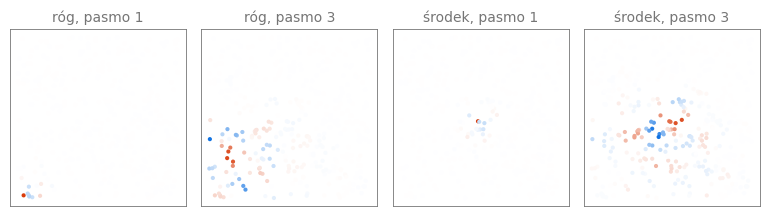

In [16]:
rog = np.argmin(np.linalg.norm(P, axis=1))
srodek = np.argmin(np.linalg.norm(P - 0.5, axis=1))
skoki = shortest_path(W > 0, unweighted=True)
fig, axs = plt.subplots(1, 4, figsize=(7.8, 2.2))
for kol, (wezel, nazwa) in enumerate(((rog, "róg"), (srodek, "środek"))):
    for w, j in enumerate((1, 3)):
        psi = U @ (G[j]*U[wezel]); mx = np.abs(psi).max()
        wezly(axs[2*kol + w], P, psi, f"{nazwa}, pasmo {j}", vmin=-mx, vmax=mx)
        e = psi**2/np.sum(psi**2)
        print(f"{nazwa:7s} pasmo {j}: norma {np.linalg.norm(psi):.3f}, "
              f"średni zasięg {np.sum(e*skoki[wezel]):.2f} skoku")
fig.tight_layout(); plt.show()
# Falki nie są przesuniętymi kopiami jednej funkcji: kształt i norma zależą od węzła.
# Przy brzegu sieci falka jest niesymetryczna, bo ma sąsiadów tylko z jednej strony.

### Ćwiczenie 14.4
Powtórz doświadczenie z kodu 14.4 dla grafów o 3, 6 i 12 sąsiadach przy błędzie czujnika równym 2. Jak liczba sąsiadów wpływa na skuteczność obu metod?

### Rozwiązanie 14.4

In [17]:
rng = np.random.default_rng(2)
for k in (3, 6, 12):
    Pk, Wk = siec(k=k)
    lk, Uk = np.linalg.eigh(np.diag(Wk.sum(axis=1)) - Wk)
    Gk = jadra(lk, lk[-1], 5)[0]
    gorne = np.sqrt(Gk[0]**2 + Gk[1]**2); nr = np.sqrt(np.sum((Uk*gorne)**2, axis=1))
    sk = Wk > 0
    traf = np.zeros(2)
    for proba in range(300):
        f = pole_temp(rng); zly = rng.integers(len(P)); f[zly] += 2.0*rng.choice([-1, 1])
        traf += [np.argmax(np.abs(Uk @ (gorne*(Uk.T @ f)))/nr) == zly,
                 np.argmax(np.abs(f - (sk @ f)/sk.sum(axis=1))) == zly]
    print(f"k = {k:2d}: falki {traf[0]/3:3.0f}, średnia sąsiadów {traf[1]/3:3.0f} na 100")
# Gęstszy graf pomaga falkom, bo lepiej opisuje gładką część pola; średniej
# sąsiadów nie pomaga, bo uśrednianie po większym obszarze gorzej śledzi pole.

k =  3: falki  47, średnia sąsiadów   4 na 100
k =  6: falki  63, średnia sąsiadów   9 na 100
k = 12: falki  68, średnia sąsiadów   5 na 100


### Ćwiczenie 14.5
Zastąp w kodzie 14.5 rozkład własny przybliżeniem Czebyszewa stopnia 40 z kodu 14.3. O ile zmienia się wynik odszumiania?

### Rozwiązanie 14.5

In [18]:
L = sparse.csr_matrix(np.diag(W.sum(axis=1)) - W)
lmax = lam[-1]
s = np.where(x + 0.3*np.sin(3*y) < 0.5, 10 + 3*y, 18 - 2*x)
snr = lambda e: 10*np.log10(np.sum((s - s.mean())**2)/np.sum((s - e)**2))
z = s + 0.5*np.random.default_rng(3).normal(size=len(P))
def odszum(filtr):
    wynik = filtr(lambda l: jadra(l, lmax, 5)[1]**2, z)
    for j in range(5):
        jadro = lambda l, j=j: jadra(l, lmax, 5)[0][j]
        w = filtr(jadro, z)
        w[np.abs(w) < 3*0.5*np.sqrt(np.sum((U*G[j])**2, axis=1))] = 0
        wynik = wynik + filtr(jadro, w)
    return wynik
dokladny = lambda jadro, f: U @ (jadro(lam)*(U.T @ f))
przyblizony = lambda jadro, f: czebyszew(L, f, jadro, lmax, 40)
print(f"rozkład własny {snr(odszum(dokladny)):.2f} dB, Czebyszew stopnia 40 "
      f"{snr(odszum(przyblizony)):.2f} dB")
# (normy falek wzięto tu z rozkładu własnego; dla dużych grafów szacuje się je,
# filtrując kilkadziesiąt losowych wektorów)

rozkład własny 17.81 dB, Czebyszew stopnia 40 17.34 dB


### Ćwiczenie 14.6
Dodaj do pola testowego z kodu 14.7 szum biały i odszum je, progując detale transformaty Haara na sferze. Porównaj błąd z błędem danych zaszumionych.

### Rozwiązanie 14.6

In [19]:
V = xyz(*srodki(32)); f = pole(V)
rng = np.random.default_rng(0)
sigma = 0.3
z = f + sigma*rng.normal(size=f.size)
a, detale = haar_sfera(z)
odsz = ihaar_sfera(a, [np.where(np.abs(d) > 3*sigma, d, 0) for d in detale])
print(f"błąd danych {np.linalg.norm(z - f)/np.linalg.norm(f)*100:.1f}%, "
      f"po progowaniu {np.linalg.norm(odsz - f)/np.linalg.norm(f)*100:.1f}%")
# Transformata jest ortonormalna, więc szum ma we wszystkich współczynnikach
# to samo odchylenie i wystarcza jeden próg, niezależnie od miejsca na sferze.

błąd danych 24.2%, po progowaniu 13.4%


### Ćwiczenie 14.7
Zbuduj graf, którego węzłami są piksele siatki HEALPix o $N_{\mathrm{side}} = 8$, łącząc każdy piksel z ośmioma najbliższymi. Porównaj kilka pierwszych wartości własnych laplasjanu z wartościami $l(l+1)$, charakterystycznymi dla harmonik sferycznych.

### Rozwiązanie 14.7

In [20]:
V = xyz(*srodki(8))
odl, sas = cKDTree(V).query(V, 9)
Ws = np.zeros((len(V), len(V)))
Ws[np.repeat(np.arange(len(V)), 8), sas[:, 1:].ravel()] = 1
Ws = np.maximum(Ws, Ws.T)
ls = np.linalg.eigvalsh(np.diag(Ws.sum(axis=1)) - Ws)
print("wartości własne / druga wartość własna * 2:")
print((2*ls[:16]/ls[1]).round(2))
print("l(l+1) z krotnością 2l+1:", [l*(l + 1) for l in range(4) for _ in range(2*l + 1)])
# Wartości własne grupują się po 1, 3, 5, 7, … i mają się do siebie w przybliżeniu
# jak 0 : 2 : 6 : 12, czyli jak l(l+1): wektory własne grafu przybliżają harmoniki sferyczne.

wartości własne / druga wartość własna * 2:
[ 0.    2.    2.06  2.07  5.6   5.61  5.89  6.58  6.87 10.24 12.17 12.19
 12.2  12.63 12.65 12.76]
l(l+1) z krotnością 2l+1: [0, 2, 2, 2, 6, 6, 6, 6, 6, 12, 12, 12, 12, 12, 12, 12]


### Ćwiczenie 14.8
Zbuduj ramę kierunkową o 16 kierunkach i powtórz ostatnią część kodu 14.8. Jak zmienia się udział energii w najsilniejszym kierunku?

### Rozwiązanie 14.8

In [21]:
n = 256
yy, xx = np.mgrid[0:n, 0:n]
for K_ in (8, 16):
    Gk = rama(n, 4, K_)[0]
    opis = f"K = {K_:2d}:"
    for kat in (0, 30, 75, 120):
        a_ = np.deg2rad(kat)
        E = np.sum(np.abs(analiza(np.cos(2*np.pi*(xx*np.cos(a_) + yy*np.sin(a_))/12), Gk))**2, axis=(0, 2, 3))
        opis += f"  {kat}°: {180*np.argmax(E)/K_:5.1f}° ({100*E.max()/E.sum():.0f}%)"
    print(opis)
# Węższe kliny dokładniej wskazują kierunek, ale udział najsilniejszego klina
# jest mniejszy, gdy kierunek leży między środkami klinów.

K =  8:  0°:   0.0° (100%)  30°:  22.5° (81%)  75°:  67.5° (82%)  120°: 112.5° (81%)
K = 16:  0°:   0.0° (100%)  30°:  33.8° (78%)  75°:  78.8° (73%)  120°: 123.8° (78%)


### Ćwiczenie 14.9
Odszum obraz pętli koronalnych z szumem o odchyleniu 15, progując moduły współczynników ramy kierunkowej (próg równy 2,5 odchylenia szumu w danym podpaśmie). Porównaj wynik z transformatą stacjonarną z kodu 10.10.

### Rozwiązanie 14.9

In [22]:
F = PETLE
G2, Q2 = rama(512, 4, 8)
normy = np.sqrt(np.sum(G2**2, axis=(2, 3)))/512        # odchylenie szumu w podpaśmie
psnr = lambda A: 10*np.log10(255**2/np.mean((F - A)**2))
def swt(Z, sigma, falka="sym4", poziomy=3):
    c = pywt.swt2(Z, falka, level=poziomy, norm=True)
    return pywt.iswt2([(cA, tuple(pywt.threshold(d, 3*sigma/2**(poziomy - i), "hard") for d in det))
                       for i, (cA, det) in enumerate(c)], falka, norm=True)
rng = np.random.default_rng(0)
sigma = 15
Z = F + sigma*rng.normal(size=F.shape)
Wz = analiza(Z, G2)
Wz = np.where(np.abs(Wz) > 2.5*sigma*normy[:, :, None, None], Wz, 0)
odsz = synteza(Wz, G2, np.fft.ifft2(np.fft.fft2(Z)*Q2).real)
print(f"dane {psnr(Z):.2f} dB, rama kierunkowa {psnr(odsz):.2f} dB, SWT sym4 {psnr(swt(Z, sigma)):.2f} dB, "
      f"filtr Gaussa {psnr(ndimage.gaussian_filter(Z, 1.5)):.2f} dB")

dane 24.60 dB, rama kierunkowa 36.31 dB, SWT sym4 36.34 dB, filtr Gaussa 36.48 dB


### Ćwiczenie 14.10
Wyznacz mapę orientacji syntetycznego obrazu współśrodkowych pierścieni i porównaj ją z kierunkiem stycznej do okręgu w każdym punkcie. Jaki jest średni błąd kąta?

### Rozwiązanie 14.10

In [23]:
n = 256
yy, xx = np.mgrid[0:n, 0:n] - n/2 + 0.5
r = np.hypot(xx, yy)
obraz = np.cos(2*np.pi*r/10)*(r > 20)
Gk = rama(n, 4, 8)[0]
E = np.sum(np.abs(analiza(obraz, Gk))**2, axis=0)
zmiennosc = 180*np.argmax(E, axis=0)/8                 # kierunek zmienności [stopnie]
promien = np.rad2deg(np.arctan2(yy, xx)) % 180          # kierunek promienia
roznica = np.abs((zmiennosc - promien + 90) % 180 - 90)
maska = (r > 30) & (r < 110)
print(f"średni błąd kąta: {roznica[maska].mean():.1f}° (szerokość klina 22,5°)")
# Kierunek zmienności pokrywa się z kierunkiem promienia, czyli struktury biegną
# stycznie; błąd nie przekracza połowy szerokości klina.

średni błąd kąta: 5.6° (szerokość klina 22,5°)
